<a href="https://colab.research.google.com/github/PGhimire-309/XAI/blob/main/SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import shap
import xgboost as xgb


X, y = shap.datasets.california()

# Train an XGBoost model
model = xgb.XGBRegressor().fit(X, y)

explainer = shap.Explainer(model)
shap_values = explainer(X)



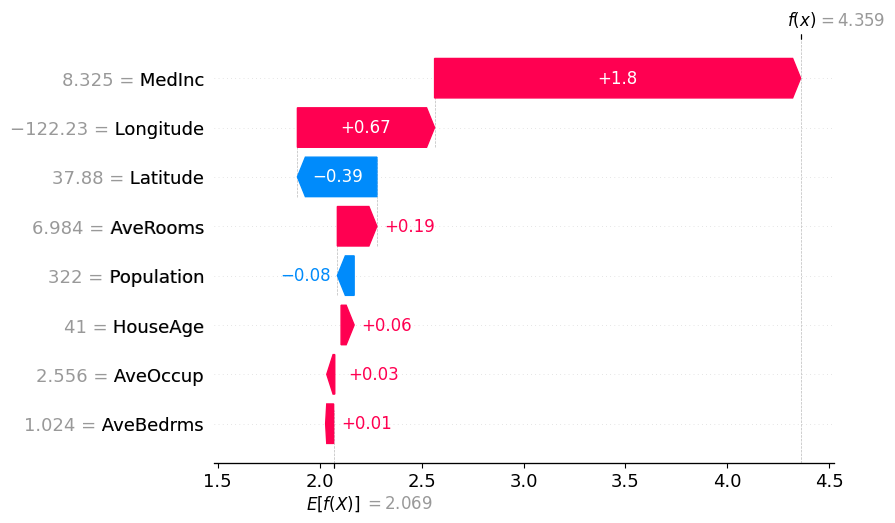

In [ ]:
# Visualize the first prediction's explanation
shap.plots.waterfall(shap_values[0])

**waterfall plot**

---
how each feature pushes the prediction from the base value (average prediction) to the final predicted house price. Red features push the prediction higher; blue features push it lower.


---



*Interpreting Waterfall model*

Suppose the base value (average predicted price) is $206,000 and the model predicts $285,000 for a specific house. The waterfall might show:

MedInc = 8.3:
+
45
,
000
+45,000 (high median income strongly increases the prediction)

AveRooms = 6.2:
+
18
,
000
+18,000

HouseAge = 52:
−
12
,
000
−12,000 (older house decreases value)

Latitude = 34.2:
−
8
,
000
−8,000

The sum of these contributions plus the base value equals the final prediction


**`Explantion TYpes`**

Global Explanations: Describe the model's overall behavior across the entire dataset. Ex: On average, Median Income is the most important feature

Local Explanations: Explain the model's behavior for one specific, single instance . Ex: Why did the model predict $285,000 for this specific house?

In [ ]:
shap.initjs()
shap.plots.force(shap_values[0])

**Force Plot (Local Explanation)**

---
The [0] is the key. It tells SHAP to pull the explanation for the first row (instance 0) in your dataset. This plot is answering the question: "Why did the model make this exact prediction for this exact house?"




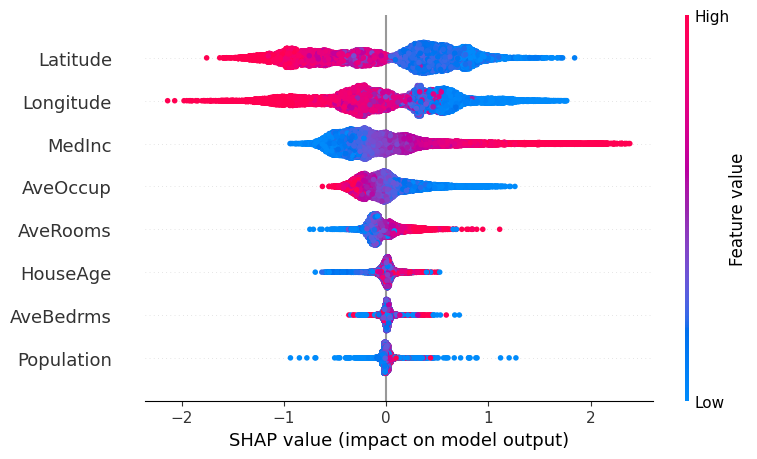

In [ ]:
shap.summary_plot(shap_values, X)

**Summary Plot (Global Explanation)**

 It tells us how the model behaves overall and what it has learned across thousands of predictions.
---
*The Clean Pattern: MedInc (Median Income)*

Look at the MedInc row. You see a very clear pattern: Blue dots on the left, Red dots on the right.

Meaning: Low median income (blue) pushes the predicted house price down (left). High median income (red) pushes the predicted price up (right). It forms a long tail to the right, meaning very high-income neighborhoods push the prediction up drastically. This is highly intuitive.

*The Complex Pattern: Latitude and Longitude*

Look at Latitude. It is the most important feature, but the colors are mixed on both sides. There are red dots on the left (high latitude pushes price down), but there is also a cluster of red dots on the right (high latitude pushes price up).

Meaning: Geography is non-linear. Because this is California housing data, a certain high latitude might be a highly desirable coastal area (like the Bay Area), pushing the price way up. But a different high latitude might be remote inland, pushing it down. The model has learned complex geographical "hotspots."

*The Ignored Features: Population*

Look at Population. The dots are tightly clustered right around the zero line.

Meaning: Whether a town has a population of 500 or 10,000, it barely changes the model's prediction. The model mostly ignores this feature.

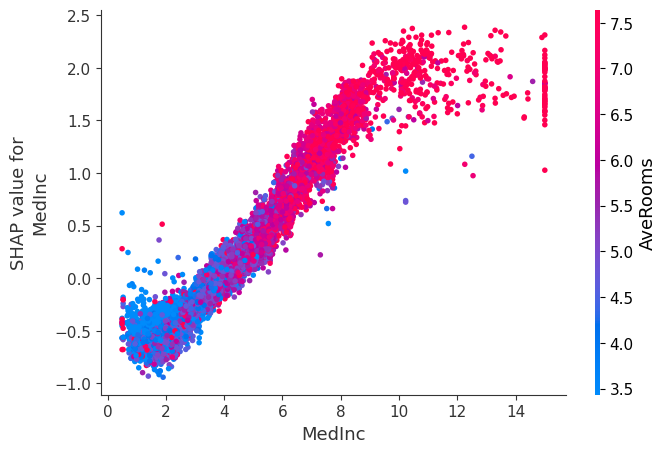

In [ ]:
shap.dependence_plot("MedInc", shap_values.values, X, interaction_index="AveRooms")

**Dependence Plot**



---

*Globally:* This plot shows the model's overall "rulebook" for Median Income: "If income is low, penalize the price. If it's medium-high, boost it significantly. If it's extremely high, don't boost it much more.

*Locally:* Every dot is a local explanation. If you look at the dot at roughly MedInc = 8.3 and SHAP = +1.8 (a red dot), that is the exact house we looked at in the Waterfall and Force plots earlier! It is sitting near the top of the curve because that specific house had very high income and many rooms.



---

**Attrubution Vs Causal**
This plot beautifully visualizes model attribution. The model relies heavily on Median Income. But as we discussed, if you artificially changed the census data to say a neighborhood makes 100k  instead of 50k, it wouldn't instantly cause the physical houses to double in value.

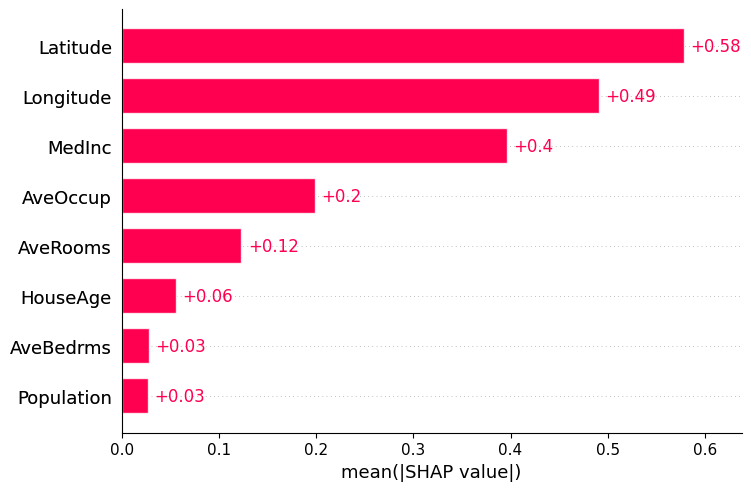

In [ ]:
shap.plots.bar(shap_values)

**Bar Plot (Global Mean |SHAP|)**



---
"What are the top 5 most important things driving the model's predictions?"

It's also useful for feature selection. If you are building a leaner model and want to drop the least useful features, the bottom bars (Population, AveBedrms, HouseAge) show you exactly which features have near-zero impact and can likely be removed without hurting the model's performance.
